# Mundial 2026 - Bloque 4

En los bloques anteriores limpiamos los datos del Mundial 2026 (Bloque 1), los analizamos con Plotly y Streamlit (Bloque 2) y construimos un cuadro de mando en Power BI (Bloque 3). En este bloque ampliamos esos datos con información externa, obtenida a través de dos APIs públicas:

- **football-data.org:** plantillas de las 48 selecciones del Mundial (con la fecha de nacimiento de cada jugador) y de los clubes de las 5 Grandes Ligas.
- **OpenStreetMap (Nominatim):** coordenadas geográficas de los 16 estadios del Mundial.

Con estos datos respondemos a tres preguntas:
1. ¿Influye el mes de nacimiento en llegar a jugar un Mundial?
2. ¿Qué peso tienen las 5 Grandes Ligas en el Mundial 2026, y cómo ha cambiado respecto a 2018 y 2022?
3. ¿Cómo se reparten los partidos y los goles entre los estadios del torneo?

### Librerías

In [1]:
import os
import re
import sys
import json
import time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly, plotly.express as px
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

#### Primero leemos la clave

Revisamos si el fichero .env existe, en ese caso nos guardamos la API. En el caso contrario, lanza un error.

In [2]:
try:
    from dotenv import load_dotenv
    load_dotenv()                      # lee el fichero .env si existe
except ImportError:
    print("python-dotenv no está instalado: se usará la variable de entorno del sistema.")

API_KEY = os.environ.get("API_FOOTBALL_KEY")

if API_KEY:
    print(f"Clave cargada")
else:
    print("No se ha encontrado API_FOOTBALL_KEY. Crea el fichero .env antes de seguir.")

Clave cargada


#### Creamos sesión con reintentos y constantes

La sesión creada utiliza: 
- La cabecera `X-Auth-Token` indica nuestra API_KEY de la API de football
- `Retry` + `mount` marcan los límites ante errores posibles(429 y 5..)

In [3]:
URL_BASE = "https://api.football-data.org/v4"

sesion = requests.Session()
sesion.headers.update({"X-Auth-Token": API_KEY or ""})
reintentos = Retry(total=3, backoff_factor=2, status_forcelist=[429, 500, 502, 503, 504])
sesion.mount("https://", HTTPAdapter(max_retries=reintentos))

# Códigos de las competiciones en football-data.org
CODIGO_MUNDIAL = "WC"
TEMPORADA_MUNDIAL = 2026
TEMPORADA_CLUBES = 2025            # temporada 2025/26: los clubes en los que jugaban durante el Mundial
LIGAS = {
    "Premier League": "PL",
    "LaLiga": "PD",
    "Bundesliga": "BL1",
    "Serie A": "SA",
    "Ligue 1": "FL1"}

PAUSA = 7
CARPETA_DATOS = Path("cache_api")
CARPETA_DATOS.mkdir(exist_ok=True)


def buscar_fichero(nombre):
    """
    Busca un fichero de datos del proyecto en la carpeta actual,
    en la superior o en datos/
    """
    for carpeta in [Path("."), Path(".."), Path("datos"), Path("../datos")]:
        if (carpeta / nombre).exists():
            return carpeta / nombre
    raise FileNotFoundError(f"No se encuentra {nombre}. Copia los Excel del Bloque 1 junto al notebook.")

#### Función para llamar a la API y función para paginación

La primera función *api_get()* hace lo siguiente: 
- Primero comprueba que los datos hayan sido descargados. En el caso de que si, los devuelve.
- Envía una petición a la API y comprueba si ha habido un error.
- Guardamos los datos en un  fichero dentro del directorio creado en el apartado anterior

In [4]:
def api_get(endpoint, params):
    nombre = endpoint.replace("/", "_") + "_" + "_".join(str(v) for v in params.values()) + ".json"
    ruta = CARPETA_DATOS / nombre

    # Si ya la teníamos guardada, la leemos del disco (no gasta llamadas)
    if ruta.exists():
        with open(ruta, "r", encoding="utf-8") as archivo:
            return json.load(archivo)

    # Si no, la pedimos a la API
    r = sesion.get(f"{URL_BASE}/{endpoint}", params=params, timeout=10)
    r.raise_for_status()
    datos = r.json()

    # Guardamos la respuesta
    with open(ruta, "w", encoding="utf-8") as archivo:
        json.dump(datos, archivo)
    print("Llamada a la API:", endpoint, params)
    time.sleep(PAUSA)
    return datos

## Ejercicio 2) Analizar la documentación de API_Football-data
Antes de programar leemos la documentación ([docs.football-data.org](https://docs.football-data.org/general/v4/)), que es el **contrato** de la API:

| Pregunta | Respuesta en football-data.org |
|---|---|
| URL | `https://api.football-data.org/v4` |
| Identificación | Cabecera `X-Auth-Token` con el token que llega por correo al registrarse |
| Devuelve | JSON. Los errores se indican con el código de estado HTTP (403, 404, 429) |
| + resultados | Estos endpoints no paginan: cada respuesta trae la competición entera |

### Endpoints que vamos a usar

| Endpoint | Parámetros | Qué devuelve | Uso |
|---|---|---|---|
| `/competitions` | — | Competiciones de nuestro plan | Comprobar el acceso |
| `/competitions/{código}/teams` | `season` | Todos los equipos de la competición **con su plantilla** (`squad`): nombre, posición, **fecha de nacimiento** y nacionalidad de cada jugador | Ejers 3 y 4 |

#### 2.1 Competiciones disponibles

In [5]:
datos = api_get("competitions", {})
competiciones = pd.json_normalize(datos["competitions"])
display(competiciones[["code", "name", "area.name"]])

necesarias = [CODIGO_MUNDIAL] + list(LIGAS.values())
faltan = [c for c in necesarias if c not in competiciones["code"].values]
if not faltan:
    print("Todas las competiciones disponibles")
else:
    print(f"Faltan: {faltan}")

,code,name,area.name
0,BSA,Campeonato Brasileiro Série A,Brazil
1,ELC,Championship,England
2,PL,Premier League,England
3,CL,UEFA Champions League,Europe
4,EC,European Championship,Europe
5,FL1,Ligue 1,France
6,BL1,Bundesliga,Germany
7,SA,Serie A,Italy
8,DED,Eredivisie,Netherlands
9,PPL,Primeira Liga,Portugal


Todas las competiciones disponibles


## Ejercicio 3) ¿Influye el mes de nacimiento en el éxito deportivo?

En el fútbol los jugadores se agrupan por año de nacimiento, y un niño nacido en enero es casi un año mayor que aquellos nacidos en diciembre. Esto significa que en los primeros años de fútbol de su vida tienen más fuerza por lo que destacan más. Veremos si esto es cierto.

#### 3.1 Extraemos los jugadores del Mundial 2026
Devuelve las 48 selecciones con su plantilla con una llamada a */competitions/WC/teams* y viene la fecha de nacimiento de cada jugador

In [6]:
datos_mundial = api_get(f"competitions/{CODIGO_MUNDIAL}/teams", {"season": TEMPORADA_MUNDIAL})
selecciones = datos_mundial["teams"]
print("Selecciones descargadas:", len(selecciones))

Selecciones descargadas: 48


#### 3.2 Pasamos los datos a un DataFrame
Cada selección tiene una lista squad con sus jugadores. Usamos pd.json_normalize con:

- record_path="squad" → una fila por cada jugador de la lista,
- meta=["name"] → copia en cada fila el nombre de la selección. Como el jugador también tiene un campo name, añadimos - - - meta_prefix="seleccion_" para que no se confundan.

In [7]:
mundial = pd.json_normalize(selecciones, record_path="squad", meta=["name"], meta_prefix="seleccion_")

mundial = mundial.rename(columns={
    "id": "id_jugador",
    "name": "nombre",
    "dateOfBirth": "fecha_nacimiento",
    "nationality": "nacionalidad",
    "position": "posicion",
    "seleccion_name": "seleccion"})

mundial = mundial[mundial["posicion"] != "Coach"] # Para que no se cuele ningún entrenador
mundial = mundial[["id_jugador", "nombre", "fecha_nacimiento", "nacionalidad", "seleccion", "posicion"]]
mundial = mundial.drop_duplicates(subset="id_jugador").reset_index(drop=True)

print("Jugadores:", len(mundial), "· Selecciones:", mundial["seleccion"].nunique())
display(mundial.head())

Jugadores: 1248 · Selecciones: 48


,id_jugador,nombre,fecha_nacimiento,nacionalidad,seleccion,posicion
0,3160,Fernando Muslera,1986-06-16,Uruguay,Uruguay,Goalkeeper
1,30210,Santiago Mele,1997-09-06,Uruguay,Uruguay,Goalkeeper
2,30386,Sergio Rochet,1993-03-23,Uruguay,Uruguay,Goalkeeper
3,3165,Guillermo Varela,1993-03-24,Uruguay,Uruguay,Defence
4,28292,Ronald Araújo,1999-03-07,Uruguay,Uruguay,Defence


#### 3.3 Columnas de fecha
Nuevo DataFrame *nacimientos* que contiene a los jugadores que tienen fecha.

In [8]:
mundial["fecha_nacimiento"] = pd.to_datetime(mundial["fecha_nacimiento"], errors="coerce")
print("Jugadores sin fecha de nacimiento:", mundial["fecha_nacimiento"].isna().sum())

nacimientos = mundial.dropna(subset=["fecha_nacimiento"]).copy()
nacimientos["mes"] = nacimientos["fecha_nacimiento"].dt.month
nacimientos["trimestre"] = "T" + nacimientos["fecha_nacimiento"].dt.quarter.astype(str)
nacimientos["semestre"] = "1er semestre"
nacimientos.loc[nacimientos["mes"] > 6, "semestre"] = "2º semestre"

print("Jugadores analizados:", len(nacimientos))

Jugadores sin fecha de nacimiento: 1
Jugadores analizados: 1247


#### 3.4 Distribución por mes
Creamos un gráfico de barras diferenciando por colores según si está por debajo o encima de lo esperado. También creamos una línea discontinua auxiliar para indicar si los nacimientos fueran los mismos en cada mes.

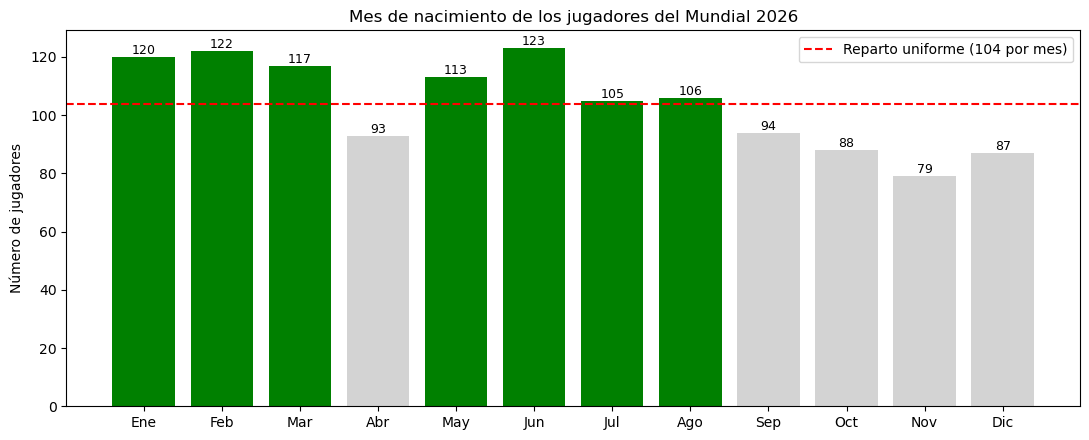

In [9]:
nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
por_mes = nacimientos["mes"].value_counts().reindex(range(1, 13), fill_value=0)
esperado = len(nacimientos) / 12

fig, ax = plt.subplots(figsize=(11, 4.5))
colores = ["green" if v > esperado else "lightgray" for v in por_mes.values] # Diferenciamos por colores
ax.bar(nombres_meses, por_mes.values, color=colores)
ax.axhline(esperado, color="red", linestyle="--", linewidth=1.5, label=f"Reparto uniforme ({esperado:.0f} por mes)")
ax.bar_label(ax.containers[0], fontsize=9)
ax.set_title("Mes de nacimiento de los jugadores del Mundial 2026")
ax.set_ylabel("Número de jugadores")
ax.legend()
plt.tight_layout()
plt.show()

#### 3.5 Distribución por trimestre
Agrupamos por trimestre para ver de una manera más visual si la tendencia es visible.

In [10]:
# Calculamos porcentajes por trimestre
por_trimestre = nacimientos["trimestre"].value_counts(normalize=True).sort_index() * 100 
por_trimestre = por_trimestre.round(1).reset_index()
por_trimestre.columns = ["trimestre", "porcentaje"]

# Los colores los hemos buscado para tener el mismo color pero de distintos tonos
fig = px.bar(por_trimestre, x="trimestre", y="porcentaje", text="porcentaje",
             color="trimestre", color_discrete_sequence= ["#0B3D2E", "#1F8A5B", "#5DB585", "#9AD3B1"],
             title="Jugadores del Mundial 2026 por trimestre de nacimiento",
             labels={"trimestre": "Trimestre de nacimiento", "porcentaje": "% de jugadores"})
fig.update_traces(texttemplate="%{text} %", textposition="outside")
fig.add_hline(y=25, line_dash="dash", line_color="red", annotation_text="reparto uniforme")
fig.update_layout(showlegend=False)
fig.show()

#### 3.6 Observamos según la posición del jugador
Agrupamos por posición, y comparamos los porcentajes en el primer semestre.

In [11]:
por_posicion = nacimientos.groupby("posicion").agg(
    jugadores=("id_jugador", "count"),
    primer_semestre=("semestre", lambda s: (s == "1er semestre").mean() * 100)).round(1).sort_values("primer_semestre", ascending=False)

display(por_posicion)

,jugadores,primer_semestre
posicion,,
Goalkeeper,145,60.7
Midfield,354,55.1
Offence,333,54.7
Defence,415,53.7


#### 3.7 Resumen

In [12]:
pct = nacimientos["trimestre"].value_counts(normalize=True).sort_index() * 100
pct_semestre1 = (nacimientos["semestre"] == "1er semestre").mean() * 100
indice_edad_relativa = pct["T1"] / pct["T4"]

print(f"Nacidos en T1: {pct['T1']:.1f} %   ·   Nacidos en T4: {pct['T4']:.1f} %")
print(f"Nacidos en el primer semestre: {pct_semestre1:.1f} % (50 % si fuera uniforme)")
print(f"Índice T1/T4: {indice_edad_relativa:.2f} → por cada jugador nacido en T4 hay {indice_edad_relativa:.2f} nacidos en T1")
print(f"Mes con más jugadores: {nombres_meses[por_mes.idxmax() - 1]} ({por_mes.max()})")
print(f"Mes con menos: {nombres_meses[por_mes.idxmin() - 1]} ({por_mes.min()})")

Nacidos en T1: 28.8 %   ·   Nacidos en T4: 20.4 %
Nacidos en el primer semestre: 55.2 % (50 % si fuera uniforme)
Índice T1/T4: 1.41 → por cada jugador nacido en T4 hay 1.41 nacidos en T1
Mes con más jugadores: Jun (123)
Mes con menos: Nov (79)


### Conclusiones del ejercicio:

- **Sí se observa el efecto de la edad relativa.** El 55,2 % de los jugadores del Mundial 2026 nació en el primer semestre del año, frente al 50 % que cabría esperar si los nacimientos se repartieran por igual.
- **La tendencia es clara por trimestres:** el porcentaje baja de forma continua, del 28,8 % en el primer trimestre al 26,4 %, 24,5 % y 20,4 % en el último. Por cada jugador nacido entre octubre y diciembre hay **1,41 nacidos entre enero y marzo**.
- Con casi 1.250 jugadores, una diferencia de 5 puntos sobre el 50 % es **difícil de atribuir al azar**.
- **Se cumple en todas las posiciones**, con más fuerza en los porteros (60,7 % nacidos en el primer semestre) y algo menos en los defensas (53,7 %).
- Por meses los datos tienen más ruido: el mes con más jugadores es junio (123) y el que menos, noviembre (79). Por eso es más fiable mirar los trimestres.

**Limitaciones:** los nacimientos en la población general tampoco son exactamente uniformes por mes, y no en todos los países el corte de las categorías inferiores coincide con el año natural. Aun así, el patrón es consistente con la hipótesis: los jugadores nacidos a principios de año, que en el fútbol base son los mayores de su categoría, tienen más posibilidades de llegar a la élite.

## Ejercicio 4) Las 5 grandes ligas en el mundial
LaLiga, Premier League, Bundesliga, Serie A  y Ligue 1 se consideran las "5 Grandes Ligas". Queremos saber cuántos de sus jugadores estuvieron en el Mundial 2026, qué ligas aportan más jugadores y cómo se reparten los jugadores de cada selección.

#### 4.1 Plantillas de los clubes de las 5 grandes ligas
Una llamada a /competitions/{código}/teams por liga (5 en total) devuelve todos sus clubes con su plantilla. Usamos la temporada 2025/26, la que estaba en curso cuando se jugó el Mundial.

In [13]:
filas = []
for nombre_liga, codigo in LIGAS.items():
    datos = api_get(f"competitions/{codigo}/teams", {"season": TEMPORADA_CLUBES})
    for equipo in datos["teams"]:
        for jugador in equipo["squad"]:
            filas.append({"id_jugador": jugador["id"], "nombre_club": jugador["name"],
                          "equipo": equipo["name"], "liga": nombre_liga})

jugadores_ligas = pd.DataFrame(filas).drop_duplicates(subset="id_jugador")
print("Jugadores en las 5 Grandes Ligas:", len(jugadores_ligas))
display(jugadores_ligas.groupby("liga").agg(equipos=("equipo", "nunique"), jugadores=("id_jugador", "count")))

Jugadores en las 5 Grandes Ligas: 3232


,equipos,jugadores
liga,,
Bundesliga,18,564
LaLiga,20,718
Ligue 1,18,600
Premier League,20,659
Serie A,20,691


#### 4.2 Juntamos los jugadores
Con un *merge* añadimos a todos los jugadores del mundial el data frame de los jugadores de las 5 grandes ligas, así ya sabemos si pertenecían a una de esas ligas. Como provienen de una misma API, los "id_jugador" son iguales

In [14]:
mundial_ligas = mundial.merge(jugadores_ligas[["id_jugador", "equipo", "liga"]], on="id_jugador", how="left")
mundial_ligas["liga"] = mundial_ligas["liga"].fillna("Otras ligas")
mundial_ligas["grande"] = mundial_ligas["liga"] != "Otras ligas"

assert len(mundial_ligas) == len(mundial), "El merge ha duplicado filas"

en_mundial = mundial_ligas["grande"].sum()

print(f"Jugadores de las 5 Grandes Ligas extraídos:  {len(jugadores_ligas)}")
print(f"De ellos, convocados en el Mundial 2026:     {en_mundial} ({en_mundial / len(jugadores_ligas):.1%})")
print(f"Peso en el Mundial: {en_mundial} de {len(mundial_ligas)} jugadores ({mundial_ligas['grande'].mean():.1%})")

Jugadores de las 5 Grandes Ligas extraídos:  3232
De ellos, convocados en el Mundial 2026:     485 (15.0%)
Peso en el Mundial: 485 de 1248 jugadores (38.9%)


#### 4.3 Observación de participaciones por liga

In [15]:
orden_ligas = list(LIGAS) + ["Otras ligas"]
colores_ligas = {"Premier League": "purple", "LaLiga": "orange", "Bundesliga": "red",
                 "Serie A": "blue", "Ligue 1": "black", "Otras ligas": "lightgray"}

por_liga = mundial_ligas["liga"].value_counts().reindex(orden_ligas).reset_index()
por_liga.columns = ["liga", "jugadores"]
por_liga = por_liga.sort_values("jugadores", ascending=False)

fig = px.bar(por_liga, x="liga", y="jugadores", text="jugadores", color="liga",
             color_discrete_map=colores_ligas,
             title="Jugadores del Mundial 2026 según la liga de su club",
             labels={"liga": "Liga", "jugadores": "Jugadores"})
fig.update_traces(textposition="outside")
fig.update_layout(showlegend=False)
fig.show()

#### 4.4 Porcentaje de 5 grandes ligas por selección
Calculamos el porcentaje de cada selección agrupando por selección y liga, y lo cambiamos a formato largo con *melt*.

In [16]:
reparto = mundial_ligas.groupby(["seleccion", "liga"]).size().unstack(fill_value=0)
reparto = reparto.reindex(columns=orden_ligas, fill_value=0)
reparto_pct = reparto.div(reparto.sum(axis=1), axis=0).mul(100).round(1)
reparto_pct = reparto_pct.sort_values("Otras ligas", ascending=False)   # arriba, las que menos dependen de las grandes ligas

reparto_largo = reparto_pct.reset_index().melt(id_vars="seleccion", var_name="liga", value_name="porcentaje")

fig = px.bar(reparto_largo, x="porcentaje", y="seleccion", color="liga", orientation="h",
             color_discrete_map=colores_ligas, category_orders={"liga": orden_ligas, "seleccion": list(reparto_pct.index)},
             title="¿Dónde juegan los jugadores de cada selección?",
             labels={"porcentaje": "% de jugadores de la selección", "seleccion": "", "liga": "Liga"},
             height=1100)
fig.update_layout(legend=dict(orientation="h", y=1.02, x=0), xaxis_range=[0, 100])
fig.show()

In [17]:
reparto_pct["% grandes ligas"] = 100 - reparto_pct["Otras ligas"]
reparto_pct["liga principal"] = reparto[list(LIGAS)].idxmax(axis=1)

print(" Selecciones con más jugadores en las 5 Grandes Ligas")
display(reparto_pct.sort_values("% grandes ligas", ascending=False)[["% grandes ligas", "liga principal"]].head())
print(" Selecciones con menos jugadores en las 5 Grandes Ligas")
display(reparto_pct.sort_values("% grandes ligas")[["% grandes ligas"]].head())
print("Selecciones sin ningún jugador en las 5 Grandes Ligas:", (reparto_pct["% grandes ligas"] == 0).sum())

 Selecciones con más jugadores en las 5 Grandes Ligas


liga,% grandes ligas,liga principal
seleccion,,
Germany,96.2,Bundesliga
Spain,96.2,LaLiga
England,96.2,Premier League
France,92.3,Ligue 1
Switzerland,88.5,Bundesliga


 Selecciones con menos jugadores en las 5 Grandes Ligas


liga,% grandes ligas
seleccion,
Curaçao,0.0
Panama,0.0
Iran,0.0
Iraq,0.0
Qatar,0.0


Selecciones sin ningún jugador en las 5 Grandes Ligas: 5


##### 4.5 Comparación con mundiales de 2018 y 2022
El mundial en 2026 ha cambiado de 32 selecciones a 48, por lo que vemos si este cambio ha afectado al peso de las grandes ligas.

,mundial,selecciones,jugadores_totales,jugadores_grandes_ligas,otras_ligas,% grandes ligas
0,2018,32,736,385,351,52.3
1,2022,32,831,417,414,50.2
2,2026,48,1248,485,763,38.9


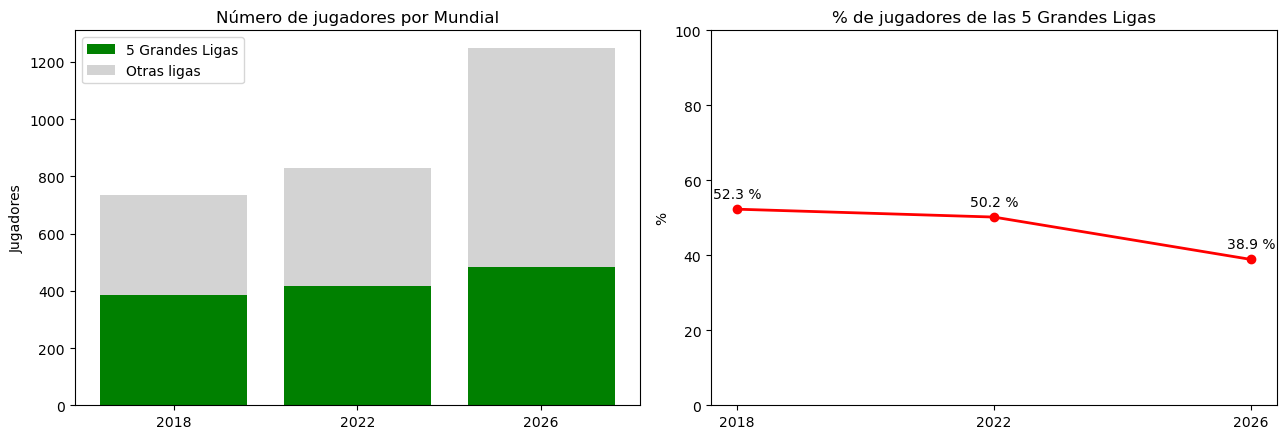

In [18]:
historico = pd.DataFrame({
    "mundial": ["2018", "2022", "2026"],
    "selecciones": [32, 32, 48],
    "jugadores_totales": [736, 831, len(mundial_ligas)],
    "jugadores_grandes_ligas": [385, 417, int(en_mundial)]})

historico["otras_ligas"] = historico["jugadores_totales"] - historico["jugadores_grandes_ligas"]
historico["% grandes ligas"] = (historico["jugadores_grandes_ligas"] / historico["jugadores_totales"] * 100).round(1)
display(historico)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(historico["mundial"], historico["jugadores_grandes_ligas"], color="green", label="5 Grandes Ligas")
axes[0].bar(historico["mundial"], historico["otras_ligas"], bottom=historico["jugadores_grandes_ligas"],color="lightgray", label="Otras ligas")
axes[0].set_title("Número de jugadores por Mundial")
axes[0].set_ylabel("Jugadores")
axes[0].legend()

axes[1].plot(historico["mundial"], historico["% grandes ligas"], marker="o", color="red", linewidth=2)
for x, y in zip(historico["mundial"], historico["% grandes ligas"]):
    axes[1].annotate(f"{y} %", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
axes[1].set_title("% de jugadores de las 5 Grandes Ligas")
axes[1].set_ylabel("%")
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

### Conclusiones del ejercicio

- **485 de los 1.248 jugadores del Mundial 2026 (38,9 %) juegan en las 5 Grandes Ligas.** Visto desde las ligas, solo el 15 % de sus 3.232 jugadores fue convocado.
- **La Premier League es la liga más representada** (159 jugadores), seguida de la Bundesliga (102), LaLiga (80), la Ligue 1 (78) y la Serie A (66). Es la liga con más capacidad económica y la que más jugadores extranjeros atrae.
- **Hay un gran contraste entre selecciones.** Alemania, España e Inglaterra tienen el 96 % de su convocatoria en las Grandes Ligas, y casi siempre en la de su propio país. En cambio, Catar, Irak, Irán, Panamá y Curazao no tienen ningún jugador en ellas: dependen de su liga nacional o de otras ligas.
- **La ampliación a 48 selecciones ha reducido el peso de las Grandes Ligas.** El número de jugadores de estas ligas sigue creciendo (385 en 2018, 417 en 2022 y 485 en 2026), pero su porcentaje cae del 52,3 % y el 50,2 % al **38,9 %**. Las 16 plazas nuevas han sido sobre todo para selecciones cuyos jugadores compiten fuera de las 5 Grandes Ligas.

**Limitaciones:** las plantillas de los clubes son las que devuelve la API para la temporada 2025/26, así que algún traspaso puede no estar reflejado. Además, en 2018 las convocatorias eran de 23 jugadores y desde 2022 son de 26, lo que también influye en los totales.

## Ejercicio 5) Analizar los datos del API OpenStreetMap

Esta API ofrece dos servicios:
- *Api v0.6*
- *Nominatim*
Como *Nominatim* ofrece búsquedas según nombres y nosotros analizaremos estadios, utilizaremos este servicio.

Observamos la información de *Nominatim*, obteniendola a partir de */search*.

| Pregunta | Respuesta |
|---|---|
| URL | `https://nominatim.openstreetmap.org/search` |
| Parámetros | `q` (texto a buscar), `format=jsonv2`, `limit` (nº de resultados), `countrycodes` (restringe a países: `us`, `mx`, `ca`) |
| Acceso | Sin usuario ni clave |
| Respuesta | Lista JSON de lugares con `lat`, `lon`, `display_name`, `category`, `type` |
| Política de uso | **Máximo 1 petición por segundo** y un `User-Agent` que identifique la aplicación |

## Ejercicio 6) Script de geolocalización de estadios

#### 6.1 Creación del excel de estadios
Obtenemos la información del excel creado en el bloque 1: "partidosWC.xlsx", creando un nuevo excel con un estadio por fila con su ciudad y país.

In [19]:
partidos = pd.read_excel(buscar_fichero("partidosWC26.xlsx"))

estadios = (partidos[["estadio", "ciudad_partido", "pais_partido"]]
            .drop_duplicates()
            .rename(columns={"ciudad_partido": "ciudad", "pais_partido": "pais"})
            .sort_values("estadio")
            .reset_index(drop=True))
estadios.to_excel("estadios_WC26.xlsx", index=False)

print("Estadios:", len(estadios))
display(estadios)

Estadios: 16


,estadio,ciudad,pais
0,Atlanta Stadium (Mercedes-Benz Stadium),Atlanta,USA
1,Boston Stadium (Gillette Stadium),Foxborough,USA
2,Dallas Stadium (AT&T Stadium),Arlington,USA
3,Guadalajara Stadium (Estadio Akron),Zapopan,MEX
4,Houston Stadium (NRG Stadium),Houston,USA
5,Kansas City Stadium (Arrowhead Stadium),Kansas City,USA
6,Los Angeles Stadium (SoFi Stadium),Inglewood,USA
7,Mexico City Stadium (Estadio Azteca),Mexico City,MEX
8,Miami Stadium (Hard Rock Stadium),Miami Gardens,USA
9,Monterrey Stadium (Estadio BBVA),Guadalupe,MEX


#### 6.2 Script
Como hay que hacer un script, lo escribimos en un fichero ".py" con "%%writefile". Añadimos una comprobación final para ver si todos los estadios se sitúan en Norteamérica.

In [20]:
%%writefile geolocalizar_estadios.py
"""
Geolocalización de estadios con OpenStreetMap (Nominatim).

Uso:
    python geolocalizar_estadios.py [excel_entrada] [excel_salida]

El Excel de entrada debe tener una columna «estadio» y, opcionalmente, «ciudad» y «pais»
(códigos de 3 letras: USA, MEX, CAN). El de salida añade latitud, longitud y la consulta usada.
"""
import re
import sys
import time

import pandas as pd
import requests

URL_NOMINATIM = "https://nominatim.openstreetmap.org/search"
HEADERS = {"User-Agent": "imat-adquisicion-mundial2026-grupo3/1.0 (proyecto docente, Comillas ICAI)"}
CODIGOS_PAIS = {"USA": "us", "MEX": "mx", "CAN": "ca"}
PAUSA = 1.1                          


# Algunos estadios llevan su nombre en paréntesis con un nombre anterior el cual no es el habitual, por lo que separamos los nombres
def separar_nombres(estadio):
    """'Dallas Stadium (AT&T Stadium)' -> ('Dallas Stadium', 'AT&T Stadium')."""
    coincidencia = re.match(r"^\s*(.+?)\s*\((.+)\)\s*$", estadio)
    if coincidencia:
        return coincidencia.group(1), coincidencia.group(2)
    return estadio.strip(), None


def consultar(texto, codigo_pais=None):
    """Hace una búsqueda en Nominatim y devuelve el primer resultado (o None)."""
    params = {"q": texto, "format": "jsonv2", "limit": 1}
    if codigo_pais:
        params["countrycodes"] = codigo_pais
    r = requests.get(URL_NOMINATIM, params=params, headers=HEADERS, timeout=10)
    r.raise_for_status()
    time.sleep(PAUSA)
    resultados = r.json()
    return resultados[0] if resultados else None


def geolocalizar(estadio, ciudad=None, pais=None):
    """Prueba varias consultas, de la más precisa a la más general."""
    nombre_fifa, nombre_comercial = separar_nombres(estadio)
    codigo_pais = CODIGOS_PAIS.get(str(pais).upper()) if pais else None

    # Vemos que nombre es el adecuado
    candidatas = []
    if nombre_comercial:
        candidatas += [f"{nombre_comercial}, {ciudad}" if ciudad else nombre_comercial, nombre_comercial]
    candidatas += [f"{nombre_fifa}, {ciudad}" if ciudad else nombre_fifa]

    for consulta in candidatas:
        resultado = consultar(consulta, codigo_pais)
        if resultado:
            return {"latitud": float(resultado["lat"]), "longitud": float(resultado["lon"]),
                    "consulta": consulta, "nombre_osm": resultado.get("display_name")}
    return {"latitud": None, "longitud": None, "consulta": None, "nombre_osm": None}


def main(entrada, salida):
    estadios = pd.read_excel(entrada)
    if "estadio" not in estadios.columns:
        raise ValueError("El Excel de entrada debe tener una columna 'estadio'")

    filas = []
    for i, fila in estadios.iterrows():
        info = geolocalizar(fila["estadio"], fila.get("ciudad"), fila.get("pais"))
        estado = "Bien" if info["latitud"] is not None else "Mal"
        print(f"{estado} [{i + 1}/{len(estadios)}] {fila['estadio']} -> {info['latitud']}, {info['longitud']}")
        filas.append(info)

    resultado = pd.concat([estadios, pd.DataFrame(filas)], axis=1)

    # Comprobación: todos los estadios del Mundial 2026 están en Norteamérica
    fuera = ~(resultado["latitud"].between(14, 60) & resultado["longitud"].between(-130, -60))
    if fuera.any():
        print(" Revisar (sin resultado o fuera de Norteamérica):", resultado.loc[fuera, "estadio"].tolist())

    resultado.to_excel(salida, index=False)
    print(f"\nGuardado en {salida}: {resultado['latitud'].notna().sum()} de {len(resultado)} estadios localizados")


if __name__ == "__main__":
    entrada = sys.argv[1] if len(sys.argv) > 1 else "estadios_WC26.xlsx"
    salida = sys.argv[2] if len(sys.argv) > 2 else "estadios_WC26_coordenadas.xlsx"
    main(entrada, salida)

Overwriting geolocalizar_estadios.py


#### 6.3 Ejecutamos script
Lo ejecutamos de forma independiente, y el *sys.executable* se asegura que el interprete de python sea el mismo que el del notebook. Al final comprobamos que todos los estadios se hayan analizado de forma correcta.

In [21]:
!"{sys.executable}" geolocalizar_estadios.py estadios_WC26.xlsx estadios_WC26_coordenadas.xlsx

Bien [1/16] Atlanta Stadium (Mercedes-Benz Stadium) -> 33.7554123, -84.4008493
Bien [2/16] Boston Stadium (Gillette Stadium) -> 42.0908879, -71.2641731
Bien [3/16] Dallas Stadium (AT&T Stadium) -> 32.7478503, -97.0928337
Bien [4/16] Guadalajara Stadium (Estadio Akron) -> 20.6818469, -103.4626718
Bien [5/16] Houston Stadium (NRG Stadium) -> 29.6848581, -95.4108015
Bien [6/16] Kansas City Stadium (Arrowhead Stadium) -> 39.0489358, -94.4839993
Bien [7/16] Los Angeles Stadium (SoFi Stadium) -> 33.9534074, -118.3390098
Bien [8/16] Mexico City Stadium (Estadio Azteca) -> 19.3029794, -99.15047
Bien [9/16] Miami Stadium (Hard Rock Stadium) -> 25.9579032, -80.2388497
Bien [10/16] Monterrey Stadium (Estadio BBVA) -> 25.6691106, -100.2444506
Bien [11/16] New York New Jersey Stadium (MetLife Stadium) -> 40.8135071, -74.0743442
Bien [12/16] Philadelphia Stadium (Lincoln Financial Field) -> 39.9009099, -75.1674892
Bien [13/16] San Francisco Bay Area Stadium (Levi's Stadium) -> 37.4029867, -121.96964

In [22]:
coordenadas = pd.read_excel("estadios_WC26_coordenadas.xlsx")
display(coordenadas[["estadio", "ciudad", "latitud", "longitud", "consulta"]])

assert coordenadas["latitud"].notna().all(), "Hay estadios sin localizar: revisa su nombre en estadios_WC26.xlsx"

,estadio,ciudad,latitud,longitud,consulta
0,Atlanta Stadium (Mercedes-Benz Stadium),Atlanta,33.755412,-84.400849,"Mercedes-Benz Stadium, Atlanta"
1,Boston Stadium (Gillette Stadium),Foxborough,42.090888,-71.264173,"Gillette Stadium, Foxborough"
2,Dallas Stadium (AT&T Stadium),Arlington,32.747850,-97.092834,"AT&T Stadium, Arlington"
3,Guadalajara Stadium (Estadio Akron),Zapopan,20.681847,-103.462672,"Estadio Akron, Zapopan"
4,Houston Stadium (NRG Stadium),Houston,29.684858,-95.410802,"NRG Stadium, Houston"
5,Kansas City Stadium (Arrowhead Stadium),Kansas City,39.048936,-94.483999,"Arrowhead Stadium, Kansas City"
6,Los Angeles Stadium (SoFi Stadium),Inglewood,33.953407,-118.339010,"SoFi Stadium, Inglewood"
7,Mexico City Stadium (Estadio Azteca),Mexico City,19.302979,-99.150470,"Estadio Azteca, Mexico City"
8,Miami Stadium (Hard Rock Stadium),Miami Gardens,25.957903,-80.238850,"Hard Rock Stadium, Miami Gardens"
9,Monterrey Stadium (Estadio BBVA),Guadalupe,25.669111,-100.244451,"Estadio BBVA, Guadalupe"


#### 6.4 Comprobación visual
Comprobamos que cada estadio haya caído en su ciudad, usando *scatter_map()*, un grafo de dispersión de toda la vida pero con un fondo geográfico.

In [23]:
fig = px.scatter_map(coordenadas, lat="latitud", lon="longitud", hover_name="estadio",
                     text="ciudad", zoom=2.6, center={"lat": 36, "lon": -98},
                     map_style="carto-positron", height=500,
                     title="Estadios del Mundial 2026 localizados con OpenStreetMap")
fig.update_traces(marker=dict(size=10, color="green"))
fig.show()

## Ejercicio 7) Dashboard interactivo de estadios
Como streamlit no funciona en jupyter, creamos un script como antes con "%%writefile". El script muestra un mapa de norteamérica con una burbuja por estadio, indicando los partidos jugados (tamaño) y los goles marcados (color). También incluye un selector, que filtra la ronda, pudiendo variar el visual según la ronda elegida. Podemos ejecutar el script con este comando en la terminal: python -m streamlit run dashboard_estadios.py.

In [24]:
%%writefile dashboard_estadios.py

from pathlib import Path

import pandas as pd
import plotly.express as px
import streamlit as st

st.set_page_config(page_title="Estadios del Mundial 2026", layout="wide")
st.title("Estadios del Mundial 2026")
st.caption("Partidos y goles por estadio - Localización: OpenStreetMap")

ORDEN_RONDAS = ["Fase de grupos", "Dieciseisavos", "Octavos", "Cuartos", "Semifinal", "Tercer puesto", "Final"]


def buscar_fichero(nombre):
    aqui = Path(__file__).parent
    for carpeta in [aqui, aqui.parent, aqui / "datos", aqui.parent / "datos", Path(".")]:
        if (carpeta / nombre).exists():
            return carpeta / nombre
    raise FileNotFoundError(nombre)


partidos = pd.read_excel(buscar_fichero("partidosWC26.xlsx"))
coordenadas = pd.read_excel(buscar_fichero("estadios_WC26_coordenadas.xlsx"))
partidos["goles"] = partidos["marcador_local"] + partidos["marcador_visitante"]

# Selector de ronda
st.sidebar.header("Filtros")
rondas = st.sidebar.multiselect("Ronda", ORDEN_RONDAS, default=ORDEN_RONDAS)

vista = partidos[partidos["ronda"].isin(rondas)]
if vista.empty:
    st.warning("Selecciona al menos una ronda.")
    st.stop()

# Partidos y goles por estadio después de filtrar
por_estadio = vista.groupby("estadio").agg(partidos=("index_partido", "count"),goles=("goles", "sum")).reset_index()
por_estadio["goles_por_partido"] = (por_estadio["goles"] / por_estadio["partidos"]).round(2)
mapa = por_estadio.merge(coordenadas[["estadio", "ciudad", "pais", "latitud", "longitud"]], on="estadio", how="left")

# Métricas
c1, c2, c3 = st.columns(3)
c1.metric("Partidos", int(mapa["partidos"].sum()))
c2.metric("Goles", int(mapa["goles"].sum()))
c3.metric("Goles por partido", f"{mapa['goles'].sum() / mapa['partidos'].sum():.2f}")

# Mapa de burbujas
fig = px.scatter_map(mapa, lat="latitud", lon="longitud",
                     size="partidos", color="goles", hover_name="estadio",
                     hover_data=["ciudad", "partidos", "goles"],
                     color_continuous_scale="YlOrRd", size_max=40,
                     center={"lat": 36, "lon": -98}, zoom=2.6,
                     map_style="carto-positron", height=620)
fig.update_layout(margin=dict(l=0, r=0, t=10, b=0))
st.plotly_chart(fig, width="stretch")

# Tabla
st.subheader("Detalle por estadio")
st.dataframe(mapa.sort_values("partidos", ascending=False)[["estadio", "ciudad", "pais", "partidos", "goles", "goles_por_partido"]],
             width="stretch", hide_index=True)

Overwriting dashboard_estadios.py


## Conclusiones finales del Bloque 4:

In [25]:
print(f"Respuestas guardadas en caché: {len(list(CARPETA_DATOS.glob('*.json')))}\n")
print(f"Nacidos en el 1er semestre: {pct_semestre1:.1f} % · Índice T1/T4: {indice_edad_relativa:.2f}")
print(f"Jugadores de las 5 Grandes Ligas en el Mundial: {en_mundial} ({mundial_ligas['grande'].mean():.1%})")
print(f"Liga más representada: {por_liga[por_liga['liga'] != 'Otras ligas'].iloc[0]['liga']}")
print(f"Estadios localizados: {coordenadas['latitud'].notna().sum()} de {len(coordenadas)}")

Respuestas guardadas en caché: 7

Nacidos en el 1er semestre: 55.2 % · Índice T1/T4: 1.41
Jugadores de las 5 Grandes Ligas en el Mundial: 485 (38.9%)
Liga más representada: Premier League
Estadios localizados: 16 de 16


| Ejercicio | Pregunta | Conclusión |
|---|---|---|
| 3 | ¿Nacen más jugadores de élite en los primeros meses del año? | Sí. El 55,2 % nació en el primer semestre y el porcentaje baja trimestre a trimestre (28,8 % en T1 frente a 20,4 % en T4), en todas las posiciones. |
| 4 | ¿Qué ligas aportan más jugadores y cómo se reparten por selección? | La Premier League (159), seguida de la Bundesliga (102). Las potencias europeas tienen más del 90 % de su plantilla en las Grandes Ligas; 5 selecciones no tienen ningún jugador en ellas. |
| 4 | ¿Ha cambiado el peso de las Grandes Ligas con 48 selecciones? | Sí. Hay más jugadores de las Grandes Ligas (485), pero su porcentaje baja del 50,2 % al 38,9 %, porque las nuevas plazas fueron para selecciones que juegan en otras ligas. |
| 7 | ¿Qué estadios concentran más partidos y goles? | Hard Rock Stadium (Miami) y MetLife Stadium (Nueva York/Nueva Jersey), con 9 partidos cada uno; Miami es el estadio con más goles (30) y MetLife acogió la final. |